# 04 — Causal estimation: clock increments and timeout losses

**Research question:** How does selecting a **+2-second per-move increment**, rather than **+0**, relate to the probability of losing on time at starting clocks of **120, 180, and 300 seconds**?

**Primary treatment:** exactly `120+2` vs `120+0`, `180+2` vs `180+0`, and `300+2` vs `300+0`. **Secondary contrast:** `300+5` vs `300+0`.

**Interpretation:** This is an observational study of *time-control queue choice*. Unadjusted, regression-adjusted, and within-player estimates remain **associations**, unless the causal identification assumptions in Notebook 3 hold. A selected queue may affect matchmaking and opponents, so the result must not be called a randomized clock-only effect.

**Workflow:** validate cohort → unadjusted risk differences → regression adjustment → dependence-aware uncertainty → standardized pooled estimates → within-player sensitivity → secondary policy → diagnostics and interpretation.


## 1. Load data and verify exact time-control policies

The notebook works when launched either from the project root or the `notebooks` directory. It does not modify source CSVs.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_cluster, cov_cluster_2groups
from scipy.stats import norm
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/processed/increment_player_games.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Put increment_player_games.csv in data/processed/ under your project root")
pg = pd.read_csv(ROOT / "data/processed/increment_player_games.csv", parse_dates=["started_at_utc"])
BASES = [120, 180, 300]
allowed = {f"{b}+{inc}" for b in BASES for inc in (0, 2)}
primary = pg.loc[pg["time_control"].isin(allowed)].copy()
primary["treated"] = primary["increment_seconds"].eq(2).astype(int)
primary["outcome"] = primary["lost_on_time"].astype(float)
primary["hour"] = primary["started_at_utc"].dt.hour + primary["started_at_utc"].dt.minute / 60
primary["hour_sin"] = np.sin(2 * np.pi * primary["hour"] / 24)
primary["hour_cos"] = np.cos(2 * np.pi * primary["hour"] / 24)
primary["elo_centred"] = (primary["player_elo"] - 1600) / 400
assert (primary.groupby("game_id").size() == 2).all()
assert (primary.groupby("game_id")["treated"].nunique() == 1).all()
assert primary[["outcome", "elo_centred", "hour_sin", "hour_cos"]].notna().all().all()
print(f"Primary cohort: {primary.game_id.nunique():,} games, {len(primary):,} player-game rows, {primary.player.nunique():,} players")
display(primary.groupby(["initial_seconds", "time_control"]).agg(games=("game_id","nunique"), timeout_risk=("outcome","mean")))

Primary cohort: 29,762 games, 59,524 player-game rows, 2,819 players


games  timeout_risk
initial_seconds time_control                     
120             120+0          5950      0.206387
                120+2          1212      0.117987
180             180+0          8243      0.207934
                180+2          1194      0.124791
300             300+0         10172      0.149725
                300+2          2991      0.111167

## 2. Unadjusted differences in timeout-loss probability

Calculate risk differences within each starting-clock stratum. Since both player perspectives come from the same game, two player observations are **not** two independent games. The confidence intervals below are deliberately based on **one row per game**. A game's outcome is the fraction of its two players who lost on time (0 or 0.5); the mean reproduces the player-game probability.

,start_seconds,control_games,treated_games,control_risk,treated_risk,risk_difference,ci_low,ci_high
0,120,5950,1212,0.2064,0.1180,-0.0884,-0.1019,-0.0749
1,180,8243,1194,0.2079,0.1248,-0.0831,-0.0965,-0.0698
2,300,10172,2991,0.1497,0.1112,-0.0386,-0.0472,-0.0299


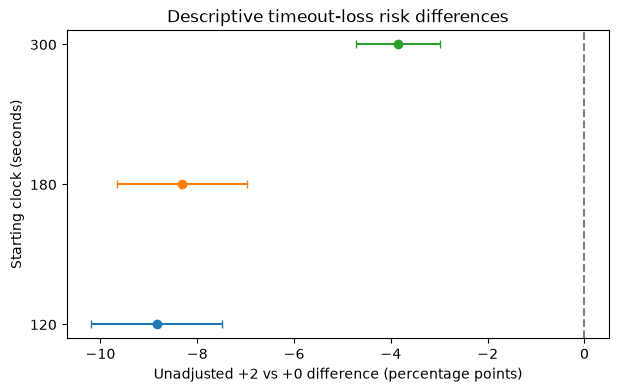

In [2]:
game_view = (primary.groupby(["initial_seconds", "game_id", "treated"], as_index=False)
             .agg(timeout_fraction=("outcome", "mean")))
rows=[]
for base, g in game_view.groupby("initial_seconds"):
    a = g.loc[g.treated.eq(1), "timeout_fraction"]
    c = g.loc[g.treated.eq(0), "timeout_fraction"]
    diff = a.mean() - c.mean()
    se = np.sqrt(a.var(ddof=1)/len(a) + c.var(ddof=1)/len(c))
    rows.append(dict(start_seconds=base, control_games=len(c), treated_games=len(a),
                     control_risk=c.mean(), treated_risk=a.mean(), risk_difference=diff,
                     ci_low=diff-1.96*se, ci_high=diff+1.96*se))
unadjusted = pd.DataFrame(rows)
display(unadjusted.round(4))
fig, ax = plt.subplots(figsize=(7,4))
for _, r in unadjusted.iterrows():
    ax.errorbar(r.risk_difference*100, str(int(r.start_seconds)),
                xerr=[[100*(r.risk_difference-r.ci_low)], [100*(r.ci_high-r.risk_difference)]],
                marker='o', capsize=3)
ax.axvline(0, ls='--', color='gray'); ax.set_xlabel('Unadjusted +2 vs +0 difference (percentage points)')
ax.set_ylabel('Starting clock (seconds)'); ax.set_title('Descriptive timeout-loss risk differences'); plt.show()

## 3. Regression-adjusted, stratum-specific associations

Use a **linear probability model (LPM)** for easily interpretable risk differences. Predictor set: queue policy (+2), focal-player Elo (scaled by 400), and cyclical UTC hour. These are **candidate pre-queue predictors**; the timestamp is a rough proxy and may not reflect the actual queue-entry time. **Do not control for opponent Elo in the primary queue-choice model:** matchmaking may occur downstream of time-control selection.

We report a point estimate alongside three sandwich-SE variants: game-clustered, focal-player-clustered, and two-way clustered by game and focal player. Two-way clustering handles those two observed membership structures, but does **not** fully account for cross-role dependence when a player's appearances as opponents are recorded in the other row. Therefore the intervals are diagnostics, not complete network-robust inference.

Fitting the primary model with a `+2 × stratum` interaction would be equivalent to fitting the policy contrast separately in each stratum; we choose the latter for clarity.

In [3]:
def fit_lpm(g, features):
    X = sm.add_constant(g[features].astype(float), has_constant="add")
    fitted = sm.OLS(g["outcome"].astype(float), X).fit()
    code_game = pd.factorize(g["game_id"])[0]
    code_player = pd.factorize(g["player"])[0]
    V_game = cov_cluster(fitted, code_game)
    V_player = cov_cluster(fitted, code_player)
    V_both, _, _ = cov_cluster_2groups(fitted, code_game, code_player)
    idx = X.columns.get_loc("treated")
    effect = fitted.params["treated"]
    results = {"estimate": effect, "N_rows": len(g), "N_games": g.game_id.nunique(),
               "N_players": g.player.nunique()}
    for label, V in [("game", V_game), ("player", V_player), ("two_way", V_both)]:
        se = np.sqrt(max(float(V[idx,idx]), 0))
        results[f"se_{label}"] = se
        results[f"ci_low_{label}"] = effect-1.96*se
        results[f"ci_high_{label}"] = effect+1.96*se
    return results

features = ["treated", "elo_centred", "hour_sin", "hour_cos"]
adjusted = pd.DataFrame([{"start_seconds": b, **fit_lpm(g, features)}
                         for b, g in primary.groupby("initial_seconds")])
display(adjusted.round(4))
print("Estimate and intervals are probabilities; multiply by 100 for percentage points.")

,start_seconds,estimate,N_rows,N_games,N_players,se_game,ci_low_game,ci_high_game,se_player,ci_low_player,ci_high_player,se_two_way,ci_low_two_way,ci_high_two_way
0,120,-0.0835,14324,7162,1174,0.0069,-0.0971,-0.0700,0.0166,-0.1161,-0.0510,0.0164,-0.1157,-0.0514
1,180,-0.0875,18874,9437,1764,0.0069,-0.1009,-0.0740,0.0163,-0.1193,-0.0556,0.0160,-0.1188,-0.0562
2,300,-0.0419,26326,13163,2021,0.0045,-0.0507,-0.0332,0.0123,-0.0660,-0.0178,0.0122,-0.0658,-0.0181


Estimate and intervals are probabilities; multiply by 100 for percentage points.


## 4. Covariate adjustment sensitivity: rating only

Compare the primary model against an Elo-only model. Important: *adjustment is not randomization*. If time-control preference or fatigue confounds selection, neither model is automatically causal.

In [4]:
elo_only = pd.DataFrame([{"start_seconds": b, **fit_lpm(g, ["treated", "elo_centred"])}
                         for b, g in primary.groupby("initial_seconds")])
comparison = (adjusted[["start_seconds", "estimate", "ci_low_two_way", "ci_high_two_way"]]
              .rename(columns={"estimate":"elo_plus_hour", "ci_low_two_way":"low_main", "ci_high_two_way":"high_main"})
              .merge(elo_only[["start_seconds", "estimate"]].rename(columns={"estimate":"elo_only"}), on="start_seconds")
              .merge(unadjusted[["start_seconds", "risk_difference"]].rename(columns={"risk_difference":"unadjusted"}), on="start_seconds"))
display(comparison.round(4))

,start_seconds,elo_plus_hour,low_main,high_main,elo_only,unadjusted
0,120,-0.0835,-0.1157,-0.0514,-0.0841,-0.0884
1,180,-0.0875,-0.1188,-0.0562,-0.0878,-0.0831
2,300,-0.0419,-0.0658,-0.0181,-0.0419,-0.0386


## 5. Within-player fixed-effects sensitivity

Restrict each stratum to players who used both +0 and +2. A within-player demeaning regression removes stable player attributes and reports a **within-switcher linear-probability association**. It does not remove time-varying confounders such as fatigue or matchmaking changes.

We include hour proxies. Rating can vary across a player's games; add it only if interpreting that rating as measured before policy choice is defensible. For transparency, our model below includes contemporaneous pre-game Elo as a covariate and explicitly notes it may partly reflect earlier treatment histories. Uncertainty is clustered by focal player, but the two player-views of a game can still be dependent.

In [5]:
def within_player(g):
    flags = g.groupby("player")["treated"].nunique()
    sub = g.loc[g["player"].isin(flags.index[flags == 2])].copy()
    cols = ["outcome", "treated", "elo_centred", "hour_sin", "hour_cos"]
    demeaned = sub[cols] - sub.groupby("player")[cols].transform("mean")
    X = demeaned[["treated", "elo_centred", "hour_sin", "hour_cos"]]
    reg = sm.OLS(demeaned["outcome"], X).fit()
    V = cov_cluster(reg, pd.factorize(sub["player"])[0])
    k = list(X.columns).index("treated")
    effect = reg.params["treated"]
    se = np.sqrt(max(float(V[k,k]), 0))
    return dict(estimate=effect, se_player=se, ci_low=effect-1.96*se,
                ci_high=effect+1.96*se, switch_players=sub.player.nunique(),
                player_game_rows=len(sub), games=sub.game_id.nunique())
within_results = pd.DataFrame([{"start_seconds": b, **within_player(g)} for b,g in primary.groupby("initial_seconds")])
display(within_results.round(4))

,start_seconds,estimate,se_player,ci_low,ci_high,switch_players,player_game_rows,games
0,120,-0.1464,0.0159,-0.1776,-0.1151,312,7691,5557
1,180,-0.1690,0.0135,-0.1955,-0.1425,389,9543,7099
2,300,-0.0850,0.0080,-0.1008,-0.0693,756,18425,11968


## 6. Exploratory pooled standardized association

Pooling the raw observations would allow differences in treatment prevalence across clock types to affect the result. Instead combine **stratum-specific adjusted associations** using weights equal to the **proportion of eligible games** at each starting clock in the primary cohort (fixed based on the cohort, before outcome analysis).

This is a descriptive standardized association, **not** an independently identified causal ATE. Stratum-specific models have disjoint games but players may appear in multiple strata, so naive cross-stratum independence of uncertainty is not assured. We report the weighted point estimate only; pooled inference would require an appropriate resampling design accounting for repeated players.

In [6]:
counts_by_clock = primary.groupby("initial_seconds")["game_id"].nunique()
weights = counts_by_clock / counts_by_clock.sum()
pooled = sum(float(weights.loc[int(r.start_seconds)] * r.estimate) for _,r in adjusted.iterrows())
print("Pre-specified game-count weights:", weights.round(3).to_dict())
print(f"Weighted adjusted association: {pooled*100:.2f} percentage points")

Pre-specified game-count weights: {120: 0.241, 180: 0.317, 300: 0.442}
Weighted adjusted association: -6.64 percentage points


## 7. Secondary analysis: 300+5 vs 300+0

This is a distinct policy comparison, not a dose-response experiment. We use the same adjustment covariates for consistency. The treatment `+5` receives a value of 1 here; the +2 observations are excluded.

In [7]:
secondary = pg.loc[pg["time_control"].isin(["300+0", "300+5"])].copy()
secondary["treated"] = secondary["increment_seconds"].eq(5).astype(int)
secondary["outcome"] = secondary["lost_on_time"].astype(float)
secondary["hour"] = secondary["started_at_utc"].dt.hour + secondary["started_at_utc"].dt.minute / 60
secondary["hour_sin"] = np.sin(2*np.pi*secondary["hour"]/24)
secondary["hour_cos"] = np.cos(2*np.pi*secondary["hour"]/24)
secondary["elo_centred"] = (secondary["player_elo"] - 1600)/400
secondary_result = fit_lpm(secondary, features)
display(pd.DataFrame([secondary_result]).round(4))

,estimate,N_rows,N_games,N_players,se_game,ci_low_game,ci_high_game,se_player,ci_low_player,ci_high_player,se_two_way,ci_low_two_way,ci_high_two_way
0,-0.0696,28958,14479,2129,0.0038,-0.077,-0.0621,0.0114,-0.092,-0.0471,0.0114,-0.0918,-0.0473


## 8. Robustness and diagnostic checks

- Compare adjusted, unadjusted, and within-player estimates; large differences indicate model dependence.
- Inspect influence of very active players: cap the number of games a focal player contributes (sensitivity only), keeping the exact policy definition.
- Check regression predictions outside [0,1]: they are allowed in LPM but signal limitations of probability-scale modeling.
- Future work: flexible models, propensity-weight diagnostics, unmeasured-confounding sensitivity, stronger network dependence adjustments, and explicit outcome-definition checks.

The following activity-capped analysis is **not** a preferred causal estimate: dropping player perspectives can break the symmetry between White and Black for a game and change the target population.

In [8]:
def cap_player_rows(g, cap=100):
    # Deterministic ordering, not outcome dependent
    return (g.sort_values(["started_at_utc", "game_id", "color"])
             .groupby("player", sort=False).head(cap).copy())
capped_rows = []
for b, g in primary.groupby("initial_seconds"):
    cap = cap_player_rows(g)
    result = fit_lpm(cap, features)
    capped_rows.append({"start_seconds":b, "capped_n":len(cap), "capped_estimate":result["estimate"],
                        "full_estimate":float(adjusted.set_index("start_seconds").loc[b, "estimate"])})
display(pd.DataFrame(capped_rows).round(4))
for b, g in primary.groupby("initial_seconds"):
    X = sm.add_constant(g[features].astype(float), has_constant="add")
    reg = sm.OLS(g.outcome, X).fit()
    pred = reg.predict(X)
    print(f"{b}s: predicted risks outside [0,1]: {((pred<0)|(pred>1)).mean():.2%}")

,start_seconds,capped_n,capped_estimate,full_estimate
0,120,11715,-0.0924,-0.0835
1,180,15654,-0.0885,-0.0875
2,300,21839,-0.0405,-0.0419


120s: predicted risks outside [0,1]: 0.41%
180s: predicted risks outside [0,1]: 0.01%
300s: predicted risks outside [0,1]: 0.00%


## 9. Export lightweight results

In [9]:
out = ROOT / "results" / "tables"
out.mkdir(parents=True, exist_ok=True)
for name, tab in [("04_unadjusted.csv", unadjusted), ("04_adjusted.csv", adjusted),
                  ("04_model_comparison.csv", comparison), ("04_within_player.csv", within_results)]:
    tab.to_csv(out / name, index=False)
print("Saved:", [p.name for p in sorted(out.glob("04_*.csv"))])

Saved: ['04_adjusted.csv', '04_model_comparison.csv', '04_unadjusted.csv', '04_within_player.csv']


## 10. Results and Interpretation

### A. Primary Adjusted Associations

Regression-adjusted linear probability models consistently found a negative association between selecting a 2-second increment and the probability of losing on time.

The models adjusted for player Elo and cyclical UTC-hour variables.

| Starting clock | Adjusted risk difference | Two-way cluster diagnostic 95% CI |
|---|---:|---:|
| 120 seconds | −8.35 pp | [−11.57, −5.14] |
| 180 seconds | −8.75 pp | [−11.88, −5.62] |
| 300 seconds | −4.19 pp | [−6.58, −1.81] |

The magnitudes remained similar to the unadjusted estimates, which were −8.84, −8.31, and −3.86 percentage points, respectively.

This suggests that adjusting for the measured player Elo and UTC-hour variables did not substantially explain the observed associations.

The game-count-weighted pooled adjusted association was −6.64 percentage points.

The larger negative associations occurred at 120- and 180-second starting clocks, whereas the association was smaller at 300 seconds. This pattern suggests possible heterogeneity across time controls, although statistical evidence of differences between strata was not formally evaluated.

These estimates are observational associations, not established causal treatment effects.

### B. Within-Player Sensitivity Analysis

Player fixed-effects models were fitted using players who participated in both increment and non-increment games within each starting-clock stratum.

| Starting clock | Within-player estimate | Switching players |
|---|---:|---:|
| 120 seconds | −14.64 pp | 312 |
| 180 seconds | −16.90 pp | 389 |
| 300 seconds | −8.50 pp | 756 |

All three within-player estimates remained negative and were substantially larger in magnitude than the corresponding ordinary regression-adjusted estimates.

These results indicate that the negative association persists when comparing different games played by the same individuals.

However, fixed effects only account for time-invariant player characteristics. They do not eliminate time-varying confounding from fatigue, motivation, recent performance, or changes in opponent selection.

Additionally, these estimates apply to the subgroup of players observed under both policies. Therefore, they cannot be directly interpreted as estimates for the same target population as the full-sample regression models.

### C. Model Dependence and Robustness

Three sensitivity analyses were conducted.

**Adjustment specification:** Models adjusting for player Elo alone produced results nearly identical to those adjusting for both Elo and UTC hour.

| Starting clock | Elo + UTC hour | Elo only |
|---|---:|---:|
| 120 seconds | −8.35 pp | −8.41 pp |
| 180 seconds | −8.75 pp | −8.78 pp |
| 300 seconds | −4.19 pp | −4.19 pp |

This suggests that including UTC-hour variables had relatively little influence on the estimated associations.

**Highly active players:** Limiting each player's contribution to 100 observations produced estimates of −9.24, −8.85, and −4.05 percentage points for 120-, 180-, and 300-second games, respectively.

The negative direction persisted, although the estimate for the 120-second stratum changed modestly. This restriction changes observation weighting and may break the paired-player structure of some games, so it is treated as a sensitivity diagnostic rather than a preferred estimate.

**Linear probability model predictions:** The proportions of predicted probabilities falling outside the valid [0, 1] range were 0.41%, 0.01%, and 0.00% across the three strata.

These small proportions suggest that invalid predicted probabilities were relatively uncommon, although they do not establish that the linear probability model was correctly specified.

Overall, the negative associations remained reasonably stable across the examined regression specifications and player-activity sensitivity check. The substantially larger within-player estimates nevertheless demonstrate important dependence on the analysis population and method.

### D. Secondary Increment Policy

The secondary analysis compared `300+5` with `300+0`.

The regression-adjusted difference was **−6.96 percentage points**, with a two-way cluster diagnostic 95% confidence interval of approximately [−9.18, −4.73] percentage points.

This association was more negative than the corresponding `300+2` versus `300+0` estimate of −4.19 percentage points.

However, the difference does not establish a causal dose-response relationship. Players voluntarily select time controls, and the populations selecting 2-second and 5-second increments may differ in characteristics that influence timeout risk.

A direct, appropriately adjusted comparison of increment durations would be needed to investigate this question further.

### E. Identification and Statistical Uncertainty

The primary estimand concerns the effect of selecting an increment time-control queue before matchmaking.

This is conceptually different from the clock-only effect of adding an increment while keeping both players and all other game conditions identical.

Because matchmaking may depend on queue selection, changing time controls can alter the opponents encountered. Consequently, the queue-choice effect potentially includes both clock-policy and matchmaking-related pathways.

The observational data do not guarantee exchangeability between treatment groups. Time-control preferences, time-management skills, fatigue, and player motivation remain plausible unmeasured confounders.

Statistical dependence also presents challenges. Each game contributes two player observations, and individual players appear repeatedly across games.

The two-way cluster diagnostic accounts for game identifiers and focal-player identifiers, but does not completely capture dependence across interconnected player-opponent relationships.

Therefore, reported confidence intervals should be interpreted cautiously. Additional network-aware uncertainty analysis would strengthen the final results.

### F. Conclusion

Under the models studied, **selecting a +2-second increment queue was consistently associated with a lower probability of losing on time** across 120-, 180-, and 300-second starting clocks.

The adjusted differences were approximately −8.35, −8.75, and −4.19 percentage points, respectively, with a pooled game-count-weighted adjusted association of −6.64 percentage points.

Within-player comparisons produced larger negative associations, while alternative regression specifications and restrictions on highly active players generally preserved the direction of the findings.

These results provide consistent evidence of a negative observational relationship between increment availability and timeout losses.

However, the analyses do not establish that adding a 2-second increment causally reduces timeout losses. Further work is needed to evaluate unmeasured confounding, assess sensitivity to modeling assumptions, and strengthen statistical inference.

### Limitations and Next Steps

The dataset covers January 2013 Lichess rated games and may not generalize to contemporary players or matchmaking conditions.

The main limitations are self-selection into time controls, incomplete information about game-selection circumstances, possible time-varying confounding, and dependence among repeated player observations.

The next stage should prioritize:

1. Improved uncertainty estimation accounting for repeated player-opponent interactions.
2. Sensitivity analysis for unmeasured confounding.
3. Propensity-score weighting or doubly robust estimation, with balance and weight diagnostics.
4. Comparison of alternative outcome models, including logistic regression.
5. More direct examination of treatment-effect heterogeneity across starting-clock durations.

These analyses would strengthen the robustness of the observational findings without automatically establishing causal identification.